## 1. What is in the dataset?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

In [2]:
from pathlib import Path

# Run from A4/ or A4/notebooks/.
data_dir = Path("data") if Path("data/Customer_Train.csv").exists() else Path("../data")
df_train = pd.read_csv(data_dir / "Customer_Train.csv")
df_test = pd.read_csv(data_dir / "Customer_Test.csv")

In [3]:
df_train.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,459555,Female,No,28,Yes,Artist,8.0,Low,1.0,Cat_6,B
1,465423,Male,Yes,46,Yes,Entertainment,1.0,Average,4.0,Cat_7,D
2,462941,Male,No,71,No,Lawyer,NaN,Low,2.0,Cat_6,D
3,462609,Female,Yes,52,No,Doctor,4.0,Low,1.0,Cat_4,C
4,462420,Male,No,26,Yes,Healthcare,0.0,Low,3.0,Cat_6,D


In [4]:
df_train.shape

(1838, 11)

In [5]:
df_test.shape

(789, 10)

- **Rows:** 1,838 labelled customers; 789 unlabelled test customers.
- **Target:** `Segmentation` (A–D); segment meanings are not supplied.
- **Inputs:** 9 predictors; exclude `ID`.
- **Numeric:** Age, Work_Experience, Family_Size.
- **Nominal/binary:** Gender, Profession, Ever_Married, Graduated, Var_1.
- **Ordinal:** Spending_Score — Low < Average < High.

In [6]:
print(df_train.dtypes)
print("\nUnique values:")
print(df_train.nunique())

categorical = ['Gender', 'Ever_Married', 'Graduated',
               'Profession', 'Spending_Score', 'Var_1']

for col in categorical:
    print(f"\n{col}")
    print(df_train[col].value_counts(dropna=False))

print("\nUnique IDs:", df_train['ID'].is_unique)
print("Train/test ID overlap:",
      len(set(df_train['ID']) & set(df_test['ID'])))

ID                   int64
Gender              object
Ever_Married        object
Age                  int64
Graduated           object
Profession          object
Work_Experience    float64
Spending_Score      object
Family_Size        float64
Var_1               object
Segmentation        object
dtype: object

Unique values:
ID                 1838
Gender                2
Ever_Married          2
Age                  67
Graduated             2
Profession            9
Work_Experience      15
Spending_Score        3
Family_Size           9
Var_1                 7
Segmentation          4
dtype: int64

Gender
Gender
Male      1009
Female     829
Name: count, dtype: int64

Ever_Married
Ever_Married
Yes    1050
No      757
NaN      31
Name: count, dtype: int64

Graduated
Graduated
Yes    1151
No      671
NaN      16
Name: count, dtype: int64

Profession
Profession
Artist           558
Healthcare       293
Entertainment    210
Doctor           178
Engineer         160
Lawyer           151
Exec

Training IDs are unique and do not overlap with test IDs. Var_1 has 7 categories, but its meaning is unknown.

## 2. How much data is missing?

In [7]:
df_train.isna().sum()

ID                   0
Gender               0
Ever_Married        31
Age                  0
Graduated           16
Profession          26
Work_Experience    174
Spending_Score       0
Family_Size         78
Var_1               22
Segmentation         0
dtype: int64

In [8]:
rows_with_missing_values = df_train.isna().any(axis=1)

print(f"Number of rows with missing values: {rows_with_missing_values.sum()}")
print(f"Percentage of rows with missing values: {rows_with_missing_values.mean() * 100:.2f}%")

Number of rows with missing values: 310
Percentage of rows with missing values: 16.87%


In [9]:
df_test.isna().sum()

ID                  0
Gender              0
Ever_Married       19
Age                 0
Graduated           8
Profession         12
Work_Experience    95
Spending_Score      0
Family_Size        35
Var_1              10
dtype: int64

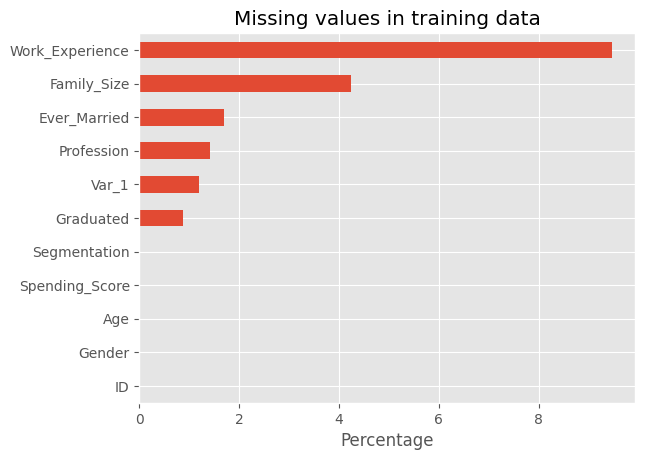

In [10]:
(df_train.isna().mean() * 100).sort_values().plot.barh()
plt.title("Missing values in training data")
plt.xlabel("Percentage")
plt.show()


- **310 rows (16.87%)** have missing values; dropping them leaves 1,528.
- **Work_Experience:** 174 missing (9.47%); missing does not mean zero.
- Keep rows and impute using training data only.

## 3. Are the classes balanced?

In [11]:
# class proportions
print(df_train["Segmentation"].value_counts())
print(df_train["Segmentation"].value_counts(normalize=True))

#duplicated rows
print(df_train.duplicated().sum())

Segmentation
A    580
D    547
B    391
C    320
Name: count, dtype: int64
Segmentation
A    0.315560
D    0.297606
B    0.212731
C    0.174102
Name: proportion, dtype: float64
0


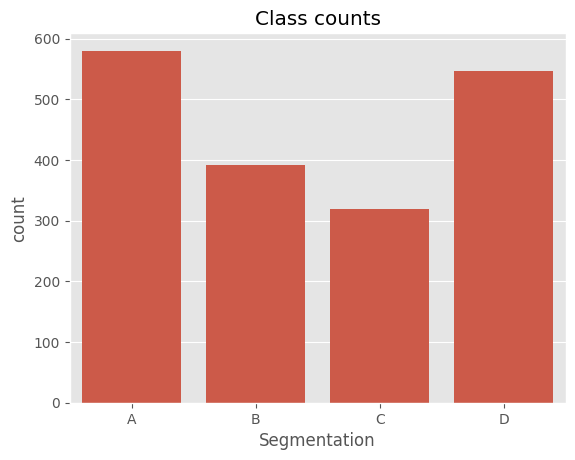

In [12]:
sns.countplot(data=df_train, x="Segmentation", order=["A", "B", "C", "D"])
plt.title("Class counts")
plt.show()


A: 31.6%, B: 21.3%, C: 17.4%, D: 29.8%. They are not equal, but no class is very rare.

Always predicting A gives 31.6% training accuracy. No complete duplicate rows were found; repeated profiles with different IDs are still possible.

## 4. What do the numeric values look like?

In [13]:
df_train.describe()

,ID,Age,Work_Experience,Family_Size
count,1838.000000,1838.000000,1664.000000,1760.000000
mean,463435.524483,43.427095,2.540865,2.817614
std,2632.230305,16.830154,3.335267,1.524940
min,458989.000000,18.000000,0.000000,1.000000
25%,461177.500000,30.000000,0.000000,2.000000
50%,463377.000000,41.000000,1.000000,2.000000
75%,465705.250000,52.000000,4.000000,4.000000
max,467961.000000,89.000000,14.000000,9.000000


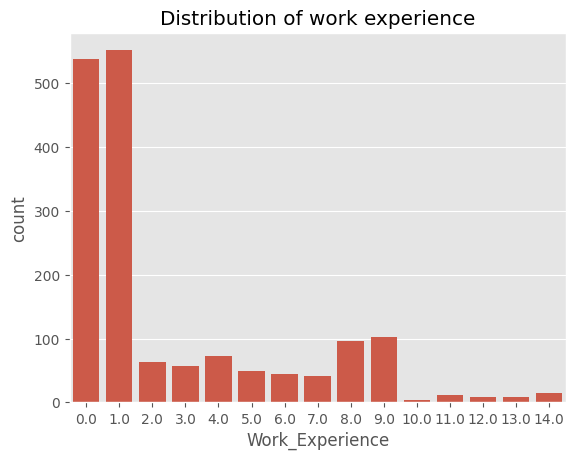

In [14]:
sns.countplot(data=df_train, x="Work_Experience")
plt.title("Distribution of work experience")
plt.show()

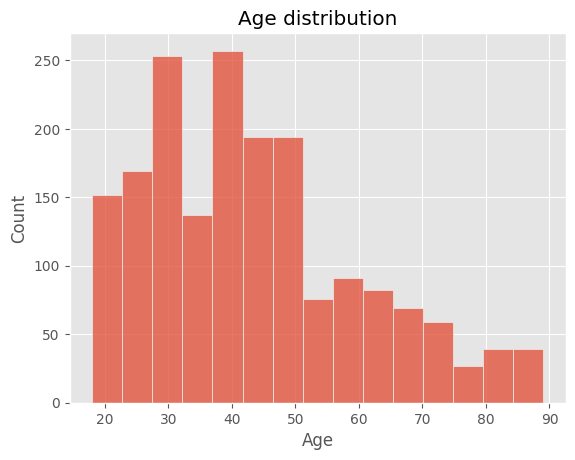

In [15]:
sns.histplot(data=df_train, x="Age", bins=15)
plt.title("Age distribution")
plt.show()

Age ranges from 18 to 89, experience from 0 to 14, and family size from 1 to 9.

Experience has mean 2.54 and median 1, suggesting a right-skewed distribution. Large values alone are not enough reason to remove rows.

## 5. What differs across segments?

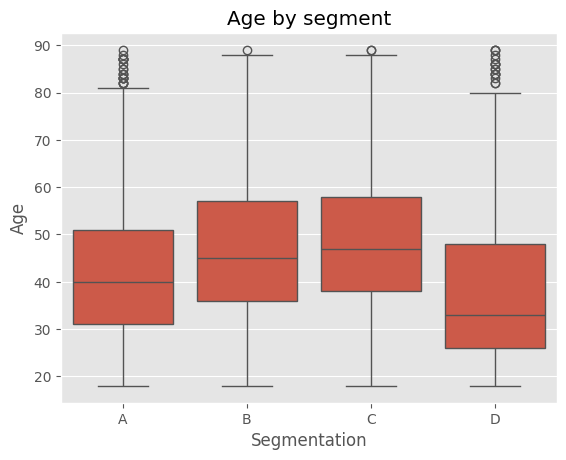

In [16]:
sns.boxplot(data=df_train, x="Segmentation", y="Age", order=["A", "B", "C", "D"])
plt.title("Age by segment")
plt.show()


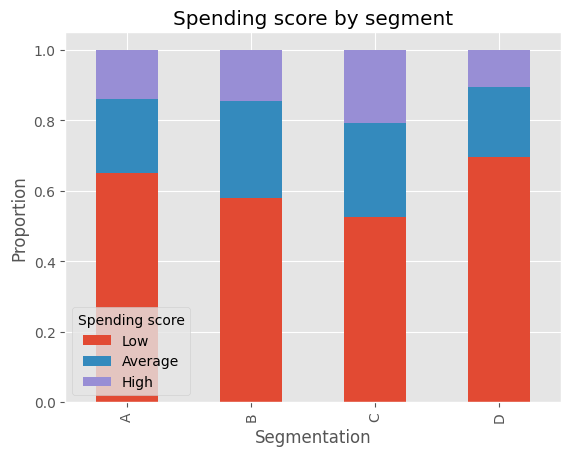

In [17]:
spending = pd.crosstab(df_train["Segmentation"], df_train["Spending_Score"], normalize="index")
spending[["Low", "Average", "High"]].plot.bar(stacked=True)
plt.title("Spending score by segment")
plt.ylabel("Proportion")
plt.legend(title="Spending score")
plt.show()


In [18]:
df_train.groupby("Segmentation")[["Age", "Work_Experience", "Family_Size"]].agg(["mean", "median", "std"]).round(2)


Age               Work_Experience              Family_Size  \
               mean median    std            mean median   std        mean   
Segmentation                                                                 
A             42.88   40.0  16.46            2.66    1.0  3.45        2.86   
B             46.29   45.0  15.67            2.44    1.0  3.30        2.67   
C             48.91   47.0  15.61            2.30    1.0  3.16        2.63   
D             38.76   33.0  17.38            2.62    1.0  3.33        2.98   

                           
             median   std  
Segmentation               
A               3.0  1.55  
B               2.0  1.56  
C               2.0  1.37  
D               3.0  1.54

In [19]:
pd.crosstab(df_train["Profession"], df_train["Segmentation"], normalize="columns").round(2)


Segmentation,A,B,C,D
Profession,,,,
Artist,0.31,0.34,0.39,0.23
Doctor,0.09,0.11,0.08,0.10
Engineer,0.09,0.10,0.10,0.07
Entertainment,0.13,0.12,0.12,0.09
Executive,0.06,0.06,0.08,0.07
Healthcare,0.15,0.11,0.07,0.27
Homemaker,0.03,0.04,0.03,0.03
Lawyer,0.08,0.09,0.11,0.07
Marketing,0.04,0.04,0.03,0.06


- **Median age:** C = 47, D = 33; distributions still overlap.
- **Healthcare:** 27% of recorded professions in D, 7% in C; missing professions are excluded.
- Profession and spending proportions are measured within each segment.
- These patterns describe the data; they do not measure feature importance.

The models use five-fold validation. See the [report](../docs/61_report_1.md) for methods and results, and the [README](../README.md) for run commands.